### Environment Setup, Data Ingestion & Anomaly Fixes

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Ingest raw records
RAW_DATA_PATH = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_raw = pd.read_csv(RAW_DATA_PATH)

print(f"Loaded raw dataset with shape: {df_raw.shape}")

# 2. Resolve whitespace anomalies in TotalCharges
# TotalCharges contains " " for brand new users (tenure == 0)
df_clean = df_raw.copy()
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

zero_tenure_mask = df_clean["TotalCharges"].isnull()
print(
    f"Identified {zero_tenure_mask.sum()} records with zero tenure and blank TotalCharges."
)
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0.0)

# 3. Target Encoding for Exploratory Analytics
df_clean["Churn_Binary"] = (df_clean["Churn"] == "Yes").astype(int)
baseline_churn_rate = df_clean["Churn_Binary"].mean()

print(f"Global Baseline Churn Rate: {baseline_churn_rate * 100:.2f}%")
df_clean.head(3)

Loaded raw dataset with shape: (7043, 21)
Identified 11 records with zero tenure and blank TotalCharges.
Global Baseline Churn Rate: 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Binary
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1


### Financial Unit Economics & Monthly Recurring Revenue (MRR) at Risk
Here, we translate churn from an abstract percentage into monetary terms by analyzing account volume, total MRR, and churned MRR across contract types:

In [2]:
# Aggregate MRR and Account metrics by Contract tier
mrr_audit = (
    df_clean.groupby("Contract")
    .agg(
        Total_Accounts=("customerID", "count"),
        Churned_Accounts=("Churn_Binary", "sum"),
        Total_MRR=("MonthlyCharges", "sum"),
        Churned_MRR=(
            "MonthlyCharges",
            lambda x: x[df_clean.loc[x.index, "Churn_Binary"] == 1].sum(),
        ),
    )
    .reset_index()
)

# Compute Business Health Indicators
mrr_audit["Retained_Accounts"] = (
    mrr_audit["Total_Accounts"] - mrr_audit["Churned_Accounts"]
)
mrr_audit["Account_Churn_Rate_%"] = (
    mrr_audit["Churned_Accounts"] / mrr_audit["Total_Accounts"] * 100
).round(2)
mrr_audit["MRR_Loss_Rate_%"] = (
    mrr_audit["Churned_MRR"] / mrr_audit["Total_MRR"] * 100
).round(2)
mrr_audit["Avg_MRR_Per_Churned_Account_$"] = (
    mrr_audit["Churned_MRR"] / mrr_audit["Churned_Accounts"]
).round(2)

print("====== Monthly Recurring Revenue (MRR) Risk Audit ======")
display(
    mrr_audit[
        [
            "Contract",
            "Total_Accounts",
            "Churned_Accounts",
            "Account_Churn_Rate_%",
            "Total_MRR",
            "Churned_MRR",
            "MRR_Loss_Rate_%",
            "Avg_MRR_Per_Churned_Account_$",
        ]
    ]
)

====== Monthly Recurring Revenue (MRR) Risk Audit ======


,Contract,Total_Accounts,Churned_Accounts,Account_Churn_Rate_%,Total_MRR,Churned_MRR,MRR_Loss_Rate_%,Avg_MRR_Per_Churned_Account_$
0,Month-to-month,3875,1655,42.71,257294.15,120847.10,46.97,73.02
1,One year,1473,166,11.27,95816.60,14118.45,14.73,85.05
2,Two year,1695,48,2.83,103005.85,4165.30,4.04,86.78


# Visualizing Tenure Survival Curves & Service Bottlenecks

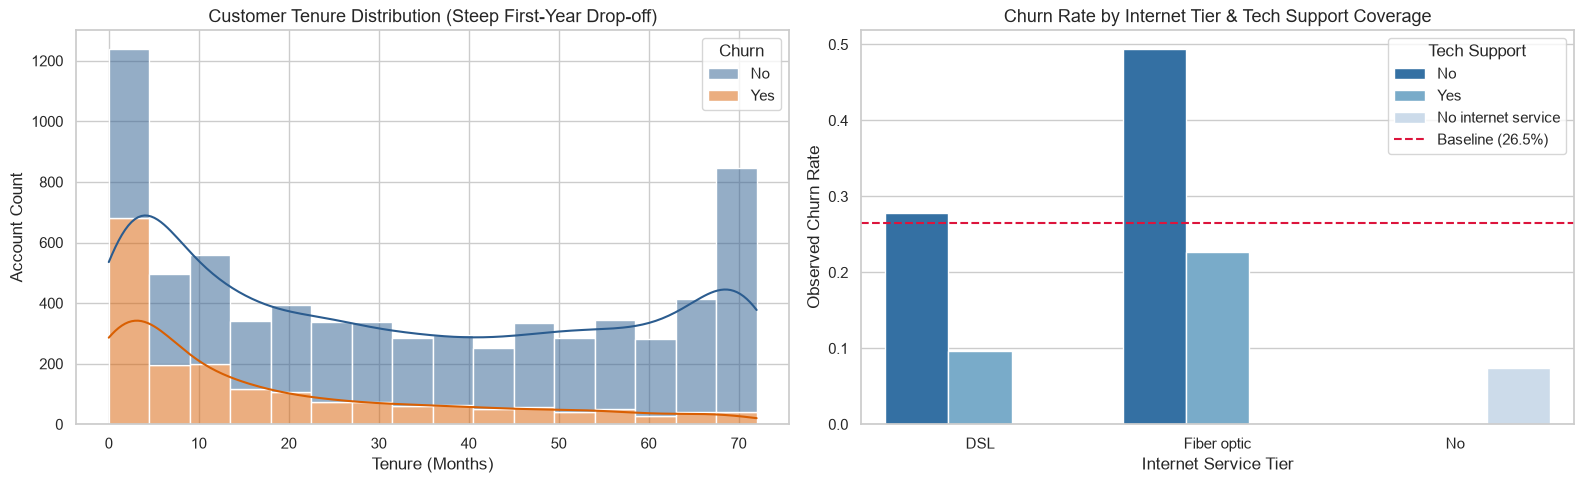

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Tenure Distribution: Churn vs Retained
sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    multiple="stack",
    kde=True,
    palette=["#2b5c8f", "#d95f02"],
    ax=axes[0],
)
axes[0].set_title(
    "Customer Tenure Distribution (Steep First-Year Drop-off)", fontsize=13
)
axes[0].set_xlabel("Tenure (Months)")
axes[0].set_ylabel("Account Count")

# 2. Service Tier Friction: Internet Service vs Tech Support Availability
service_churn = (
    df_clean.groupby(["InternetService", "TechSupport"])["Churn_Binary"]
    .mean()
    .reset_index()
)

sns.barplot(
    data=service_churn,
    x="InternetService",
    y="Churn_Binary",
    hue="TechSupport",
    palette="Blues_r",
    ax=axes[1],
)
axes[1].set_title(
    "Churn Rate by Internet Tier & Tech Support Coverage", fontsize=13
)
axes[1].set_xlabel("Internet Service Tier")
axes[1].set_ylabel("Observed Churn Rate")
axes[1].axhline(
    baseline_churn_rate,
    color="crimson",
    linestyle="--",
    label=f"Baseline ({baseline_churn_rate:.1%})",
)
axes[1].legend(title="Tech Support")

plt.tight_layout()
plt.show()

### Key Business & Analytical Insights

1. **Early Tenure Cliff:** The highest risk window occurs between months 0 and 12. Retention curves flatten significantly after month 15.
2. **Contract Type Exposure:** Month-to-month contracts represent the majority of revenue loss (>40% churn rate), while 1-year and 2-year contracts show strong retention (<12% and <3% churn rates, respectively).
3. **Tech Support Leverage:** Accounts with Fiber Optic service lacking Tech Support experience a churn rate exceeding 40%, pointing to onboarding and product-experience friction.